# PathSnap model 05: Histogram Gradient Boosting

*Family: Boosting*

**What every model in this project does.** For each GPS fix we already have a short list of *candidate* road arcs
(all arcs within 50 m, at least 5). Each (fix, candidate) pair is one row with 13 features (distance, heading
difference, …) and a label `y` = 1 if the candidate is the fix's true arc, else 0. The model learns
**P(candidate is the true arc | features)**. For each fix, the candidate with the highest probability is the
prediction. Every model notebook uses the same data, folds and metrics from `pathsnap_common.py`, so the numbers are
directly comparable.

**Metrics used below** (full definitions in the report):
- **Top-1 accuracy** (primary): share of fixes whose highest-probability candidate is the true arc.
- **Macro F1**: per trip, the F1-score of each road arc treated as a class, averaged over arcs (so short, rarely
  visited arcs count as much as long ones), then averaged over trips.
- **Log loss**: how good the probabilities are (lower is better); punishes confident mistakes.
- **Precision / recall / F1 / confusion matrix**: candidate level, "is this the true arc?" with threshold 0.5.
- **Route continuity**: share of consecutive fixes whose predicted arcs are the same or connected within 3 arcs.
- **Route F1**: length-weighted overlap between the set of predicted arcs and the reference route.

## 1. What the algorithm does

**Gradient boosting** also uses decision trees, but builds them one after another: each new small tree is fitted
to correct the errors (the gradient of the log loss) of the trees before it, and its output is added with a small
weight (the learning rate). **Histogram** gradient boosting first bins each feature into ≤ 255 buckets, which makes
finding splits very fast on millions of rows.

## 2. Why we tried it for PathSnap, strengths and limitations

- Same strengths as trees (thresholds, interactions, no scaling), but boosting usually reaches lower error than
  averaging (bagging) because each tree focuses on what is still wrong.
- It optimises **log loss directly**, so its probabilities are usually well calibrated, which matters for the
  HMM emission scores.
- **Strengths:** state-of-the-art accuracy on tabular data, fast on 1.8 M rows, small model file, built-in
  regularisation (leaf limits, L2, learning rate).
- **Limitations:** more hyperparameters that interact (learning rate × number of trees), sequential training
  (cannot parallelise across trees), can overfit if trees are too large or too many.

### Hyperparameters (initial values) and training objective

| Hyperparameter | Initial value | Meaning |
|---|---|---|
| `max_iter` | 200 | number of boosting iterations (trees) |
| `learning_rate` | 0.1 | weight of each new tree |
| `max_leaf_nodes` | 31 | size of each tree |
| `min_samples_leaf` | 20 | minimum rows in a leaf |
| `l2_regularization` | 0 | penalty on leaf values |
| `max_bins` | 255 | histogram buckets per feature |
| `early_stopping` | off | fixed number of trees, so every fold trains identically |
| `FRAC` | 0.4 | 40% of training fixes (≈ 580 k rows per fold) |


**Loss:** binary cross-entropy (log loss). Each iteration fits a tree to the gradient and hessian of the log loss
(a second-order, Newton-style step). Because the trees are added one at a time, boosting **does** have an
iteration-wise history; section 5 plots train and validation log loss per iteration.

### Setup: load the candidate tables

In [1]:
import sys, time, json
sys.path.insert(0, ".")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathsnap_common import *

train = load_partition("train")          # every candidate row of the 80 train trips
test = load_partition("student_test")    # every candidate row of the 10 student_test trips
print(f"train: {len(train):,} rows ({train.keep_train.sum():,} with reliable labels) | student_test: {len(test):,} rows")
print("features:", FEATURES)

train: 2,103,209 rows (1,801,387 with reliable labels) | student_test: 222,004 rows
features: ['dist', 'dist_rank', 'dist_gap', 'heading_diff', 'speed', 'along_t', 'arc_len', 'has_twin', 'junction_deg', 'n_cand20', 'n_cand50', 'nbr_dist', 'conn_prev']


### Model definition

In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier

NAME, TITLE, FAMILY = "hist_gradient_boosting", "Histogram Gradient Boosting", "Boosting"
FRAC, SAVE_MODEL = 0.4, True
CONFIG = dict(max_iter=200, learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=0.0,
              max_bins=255, early_stopping=False, loss="log_loss", train_frac=FRAC, random_state=SEED)


def make_model():
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=20,
                                          l2_regularization=0.0, early_stopping=False, random_state=SEED)

## 3. Cross-validation (GroupKFold by trip, 5 folds)

The 80 train trips are split into 5 groups of 16. Each fold trains on 64 trips and predicts the 16 held-out trips,
so the model is always scored on trips it has never seen (fixes of one trip are nearly identical, so mixing them
would inflate scores). Training uses a random `FRAC` share of the reliable-label fixes of the 64 trips (all
candidates of a chosen fix stay together); prediction covers every candidate of the held-out trips.
We also score the model on (a sample of) the fixes it was trained on: a large train/validation gap means
**overfitting**; low scores on both mean **underfitting**.

[hist_gradient_boosting] fold 1: train top-1 0.8794 | val top-1 0.8555 | val log loss 0.0940 | fit 6s


[hist_gradient_boosting] fold 2: train top-1 0.8768 | val top-1 0.9007 | val log loss 0.0623 | fit 6s


[hist_gradient_boosting] fold 3: train top-1 0.8873 | val top-1 0.8526 | val log loss 0.0777 | fit 7s


[hist_gradient_boosting] fold 4: train top-1 0.8742 | val top-1 0.9148 | val log loss 0.0520 | fit 9s


[hist_gradient_boosting] fold 5: train top-1 0.8962 | val top-1 0.8256 | val log loss 0.1071 | fit 8s


CV done in 63 s


,fold,train_rows,fit_s,train_top1,val_top1,train_logloss,val_logloss,val_macro_f1,val_precision,val_recall,val_f1,val_continuity,val_route_f1
0,1,576525,6.3411,0.8794,0.8555,0.0609,0.0940,0.6716,0.8597,0.8499,0.8548,0.9477,0.8265
1,2,579422,6.1931,0.8768,0.9007,0.0661,0.0623,0.7989,0.8978,0.8820,0.8898,0.9444,0.9049
2,3,574769,6.6527,0.8874,0.8526,0.0610,0.0777,0.7211,0.8634,0.8358,0.8494,0.9733,0.8677
3,4,575011,8.5972,0.8742,0.9148,0.0670,0.0520,0.7998,0.9096,0.9052,0.9074,0.9697,0.9066
4,5,575532,8.4972,0.8962,0.8256,0.0540,0.1071,0.6851,0.8290,0.8234,0.8262,0.9744,0.8249


mean ± std  val top-1 86.99% ± 3.69% | val macro F1 0.7353 ± 0.0612 | val log loss 0.0786


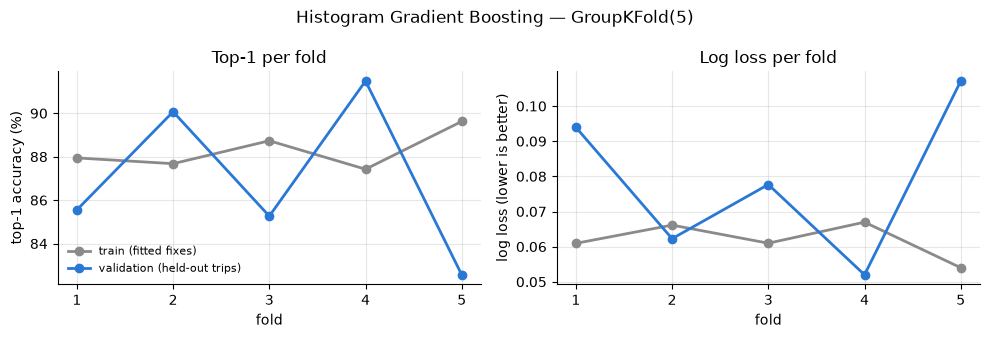

In [3]:
t0 = time.time()
cv, oof, cv_models = run_cv(make_model, train, FRAC, label=NAME)
print(f"CV done in {time.time() - t0:.0f} s")
show = ["fold", "train_rows", "fit_s", "train_top1", "val_top1", "train_logloss", "val_logloss", "val_macro_f1",
        "val_precision", "val_recall", "val_f1", "val_continuity", "val_route_f1"]
display(cv[show].round(4))
print("mean ± std  val top-1 {:.2%} ± {:.2%} | val macro F1 {:.4f} ± {:.4f} | val log loss {:.4f}".format(
    cv.val_top1.mean(), cv.val_top1.std(), cv.val_macro_f1.mean(), cv.val_macro_f1.std(), cv.val_logloss.mean()))
fig = plot_cv(cv, TITLE + " — GroupKFold(5)")
(OUT_DIR / NAME).mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / NAME / "fig_cv.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Final fit on all 80 train trips and evaluation on student_test

Refit with the same recipe on the reliable-label fixes of all 80 train trips, then score every candidate of the 10
student_test trips. student_test is used only for this development-stage comparison, never for training.
**Inference time** is the time `predict_proba` takes for all student_test candidates, per 1 000 GPS fixes
(features are already computed; feature building is the same for every model).

,student_test
top1,0.8864
top1_all,0.8618
macro_f1,0.7548
logloss,0.0637
precision,0.8807
recall,0.8821
f1,0.8814
continuity,0.9691
route_f1,0.9011
fit_s,8.6791


,trip,n_fix,top1,macro_f1,continuity,route_f1
0,00000000,2503,0.9441,0.7369,0.9852,0.9678
1,00000007,1354,0.9898,0.9496,0.9985,0.9840
2,00000009,1049,0.8541,0.7635,0.9485,0.8747
3,00000040,2995,0.9428,0.7925,0.9906,0.9276
4,00000052,262,0.9580,0.8304,0.9732,0.9306
5,00000056,3958,0.8944,0.8185,0.9371,0.9095
6,00000065,768,0.8372,0.7218,0.9700,0.8945
7,00000076,1486,0.8634,0.6218,0.9367,0.8345
8,00000077,3911,0.7669,0.5853,0.9875,0.7691
9,00000091,874,0.8570,0.7277,0.9450,0.9182


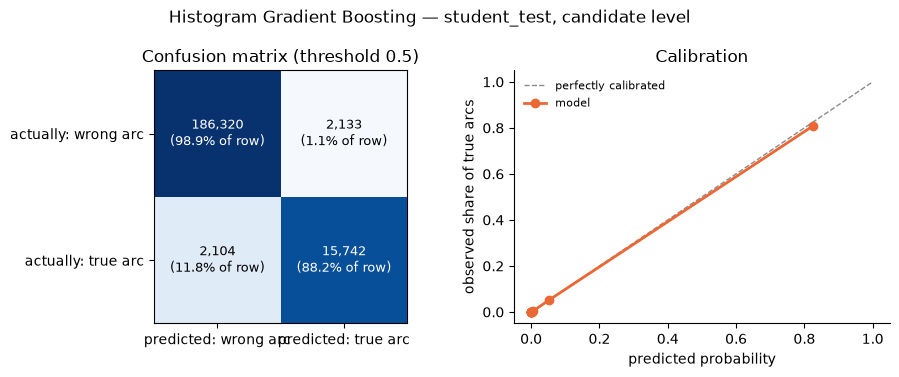

In [4]:
final_model, p_test, test_res, test_preds = fit_and_test(make_model, train, test, FRAC)
keys = ["top1", "top1_all", "macro_f1", "logloss", "precision", "recall", "f1", "continuity", "route_f1",
        "fit_s", "predict_ms_per_1k_fixes"]
display(pd.Series({k: test_res[k] for k in keys}).to_frame("student_test").round(4))
display(pd.DataFrame(test_res["per_trip"]).assign(trip=lambda d: [trips("student_test")[t] for t in d.tidx])
        .assign(top1=lambda d: d.correct_kept / d.n_kept)[["trip", "n_fix", "top1", "macro_f1", "continuity", "route_f1"]].round(4))
fig = plot_confusion_and_calibration(test, p_test, TITLE)
fig.savefig(OUT_DIR / NAME / "fig_confusion_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Iteration-wise training history (fold 1)

For each boosting iteration we compute the log loss on (a) the fixes fold 1 was trained on and (b) its 16 held-out
trips, using `staged_predict_proba`. If validation loss starts rising while training loss keeps falling, the model
is overfitting.

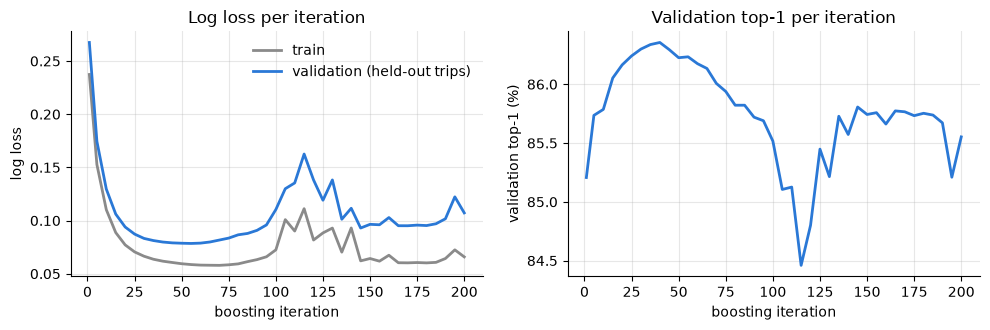

,iteration,train_logloss,val_logloss,val_top1
38,190,0.0643,0.1017,0.8567
39,195,0.0725,0.1223,0.8521
40,200,0.0658,0.1072,0.8555


In [5]:
folds = make_folds(train)
gid, X, y = train.gid.values, matrix(train), train.y.values
is_val = np.isin(train.tidx.values, folds[0])
tr = subsample_fixes(np.flatnonzero(~is_val & train.keep_train.values), gid, FRAC, SEED + 0)
tr_s = subsample_fixes(tr, gid, 20_000 / len(np.unique(gid[tr])), SEED)
va = np.flatnonzero(is_val & train.keep_train.values)
m0 = cv_models[0]
hist = []
for it, (pt, pv) in enumerate(zip(m0.staged_predict_proba(X[tr_s]), m0.staged_predict_proba(X[va])), 1):
    if it % 5 == 0 or it == 1:
        hist.append(dict(iteration=it, train_logloss=log_loss(y[tr_s], pt[:, 1]), val_logloss=log_loss(y[va], pv[:, 1]),
                         val_top1=quick_top1_logloss(gid[va], y[va], pv[:, 1])[0]))
hist = pd.DataFrame(hist); hist.to_csv(OUT_DIR / NAME / "boosting_history_fold1.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(hist.iteration, hist.train_logloss, color=GREY, lw=2, label="train")
ax[0].plot(hist.iteration, hist.val_logloss, color=BLUE, lw=2, label="validation (held-out trips)")
ax[0].set(xlabel="boosting iteration", ylabel="log loss", title="Log loss per iteration"); ax[0].legend(frameon=False)
ax[1].plot(hist.iteration, hist.val_top1 * 100, color=BLUE, lw=2)
ax[1].set(xlabel="boosting iteration", ylabel="validation top-1 (%)", title="Validation top-1 per iteration")
for a in ax: a.grid(alpha=.3); a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / NAME / "fig_history.png", dpi=150); plt.show()
hist.tail(3).round(4)

## Save results

Writes `results/<model>/results.json` (config, CV mean/std, student_test metrics), the per-fold table, per-trip student_test table, out-of-fold probabilities (used by the comparison and HMM notebooks) and the fitted model.

In [6]:
summary = save_results(NAME, FAMILY, CONFIG, cv, test_res, model=final_model if SAVE_MODEL else None,
                       oof=oof, p_test=p_test)
print(json.dumps({k: summary[k] for k in ["name", "family", "config"]}, indent=1))
print("saved to", OUT_DIR / NAME)

{
 "name": "hist_gradient_boosting",
 "family": "Boosting",
 "config": {
  "max_iter": 200,
  "learning_rate": 0.1,
  "max_leaf_nodes": 31,
  "min_samples_leaf": 20,
  "l2_regularization": 0.0,
  "max_bins": 255,
  "early_stopping": false,
  "loss": "log_loss",
  "train_frac": 0.4,
  "random_state": 42
 }
}
saved to /home/av8/Documents/ML/Hackathon/results/hist_gradient_boosting
